# Pneumonia Detection from Paediatric Chest X-Rays

**Course:** CSE 443 — Problem Set 01

## The task

Classify anterior-posterior chest X-rays of children aged 1–5 as **NORMAL** or **PNEUMONIA**,
using a convolutional neural network built and trained from scratch in PyTorch.

## Why the metric choice matters here

This is a screening problem in a clinical setting, so the two errors are not symmetric:

- A **false negative** is a child with pneumonia sent home untreated.
- A **false positive** is a child flagged for a radiologist to look at again.

Those costs are nowhere near equal. So while I report accuracy, the model is selected and the
decision threshold tuned around **recall on the pneumonia class**, with precision watched so the
model does not degenerate into predicting "pneumonia" for everyone.

## Dataset

5,856 JPEG images in the standard `train` / `val` / `test` folder layout, two classes each.
The data is imbalanced — pneumonia outnumbers normal roughly 3:1 in the training set — and the
provided `val` folder contains only **16 images**, which is far too small to steer training. Both
issues are dealt with explicitly below.

## Notebook outline

1. Inventory and integrity audit of the image files (duplicates, cross-split leakage, patient IDs)
2. Visual inspection and image-property statistics
3. Preprocessing and an in-memory image cache
4. A **patient-grouped** train/validation split
5. Augmentation chosen for chest radiographs specifically
6. CNN architecture, class-weighted loss, training loop with early stopping
7. Threshold selection on validation, then a single final evaluation on the test set
8. Error analysis (bacterial vs viral pneumonia) and Grad-CAM interpretability

## 0. Setup

In [1]:
import hashlib
import json
import random
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Apple silicon exposes its GPU through the Metal Performance Shaders backend.
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "chest_xray"
CACHE_DIR = ROOT / "data" / "cache"
FIG_DIR = ROOT / "results" / "figures"
RESULT_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
for d in (CACHE_DIR, FIG_DIR, RESULT_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 180
CLASSES = ["NORMAL", "PNEUMONIA"]   # index 0 = NORMAL, index 1 = PNEUMONIA (positive class)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
NORMAL_COLOR, PNEU_COLOR = "#4C72B0", "#C44E52"

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png")

print(f"torch {torch.__version__}   device: {DEVICE}")

torch 2.9.1   device: mps


## 1. File inventory

In [2]:
records = []
for split in ["train", "val", "test"]:
    for label, cls in enumerate(CLASSES):
        for path in sorted((DATA_DIR / split / cls).glob("*.jpeg")):
            records.append({"path": path, "split": split, "cls": cls, "label": label,
                            "filename": path.name})
files = pd.DataFrame(records)
print(f"total images found: {len(files):,}\n")

inventory = files.pivot_table(index="split", columns="cls", values="filename",
                              aggfunc="count").loc[["train", "val", "test"]]
inventory["total"] = inventory.sum(axis=1)
inventory["pneumonia_%"] = (100 * inventory["PNEUMONIA"] / inventory["total"]).round(1)
inventory

total images found: 5,856



cls,NORMAL,PNEUMONIA,total,pneumonia_%
split,,,,
train,1341,3875,5216,74.3
val,8,8,16,50.0
test,234,390,624,62.5


Two things to flag straight away:

- The **validation folder has 16 images**. Eight per class. A validation set that small gives an
  accuracy estimate with an error bar of roughly ±12 percentage points — you cannot use it to
  choose when to stop training or where to put a decision threshold. I build a proper validation
  split instead (section 4) and keep these 16 images inside the training pool.
- The training set is **74% pneumonia**. Left alone, a network will learn that guessing
  "pneumonia" is a good default. Handled with a weighted loss in section 6.

## 2. Integrity audit

Before training anything I want to know whether the dataset splits are actually clean. Three
specific checks:

1. Are there **exact duplicate images**?
2. Does any image appear in **more than one split** (which would invalidate the test set)?
3. The filenames encode patient identity (`person617_bacteria_2288.jpeg`). Do **multiple images
   come from the same patient**? If so, a naive random train/validation split would put one
   patient's X-rays on both sides and inflate the validation score.

In [3]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

files["md5"] = files["path"].map(file_hash)

dup_groups = files.groupby("md5").filter(lambda g: len(g) > 1)
n_dup_groups = dup_groups["md5"].nunique()
cross_split = (
    dup_groups.groupby("md5")["split"].nunique().gt(1).sum()
)
print(f"exact-duplicate groups           : {n_dup_groups}")
print(f"  ...spanning different splits   : {cross_split}")
print(f"redundant images (duplicates)    : {len(dup_groups) - n_dup_groups}")

if n_dup_groups:
    print("\nexamples:")
    for _, g in list(dup_groups.groupby('md5'))[:4]:
        print("  ", " == ".join(f"{r.split}/{r.cls}/{r.filename}" for r in g.itertuples()))

exact-duplicate groups           : 30
  ...spanning different splits   : 0
redundant images (duplicates)    : 32

examples:
   test/NORMAL/NORMAL2-IM-0246-0001-0001.jpeg == test/NORMAL/NORMAL2-IM-0246-0001-0002.jpeg
   train/PNEUMONIA/person1619_bacteria_4267.jpeg == train/PNEUMONIA/person1619_bacteria_4268.jpeg
   train/PNEUMONIA/person1349_bacteria_3436.jpeg == train/PNEUMONIA/person1349_bacteria_3437.jpeg
   train/PNEUMONIA/person1481_bacteria_3866.jpeg == train/PNEUMONIA/person1481_bacteria_3867.jpeg


**No duplicate image appears in more than one split.** The official test set is not contaminated
by the training set, so test numbers reported later are trustworthy. There are 30 duplicate pairs
*inside* the training folder; I drop the redundant copy of each so the model does not see the
same image twice per epoch.

In [4]:
def patient_id(row):
    """Extract a patient identifier from the filename.

    Pneumonia files look like `person617_bacteria_2288.jpeg`; normal files are either
    `IM-0115-0001.jpeg` or `NORMAL2-IM-0588-0001.jpeg`. The numbering restarts per class,
    so the class is folded into the id to keep the groups distinct.
    """
    name = row["filename"]
    m = re.match(r"person(\d+)_", name)
    if m:
        return f"pneu_p{m.group(1)}"
    m = re.match(r"(NORMAL2-)?IM-(\d+)-", name)
    if m:
        return f"norm_{'a' if m.group(1) else 'b'}{m.group(2)}"
    return f"unmatched_{name}"

files["patient"] = files.apply(patient_id, axis=1)
print("filenames not matching any known pattern:",
      (files["patient"].str.startswith("unmatched")).sum())

grp = files.groupby("split")["patient"].agg(images="size", patients="nunique")
grp["images_per_patient"] = (grp["images"] / grp["patients"]).round(2)
print()
print(grp.to_string())

multi = files.groupby(["split", "patient"]).size()
print(f"\npatients contributing more than one image (train): "
      f"{(multi.loc['train'] > 1).sum()} of {multi.loc['train'].size}")
print(f"largest single-patient group (train): {multi.loc['train'].max()} images")

filenames not matching any known pattern: 0

       images  patients  images_per_patient
split                                      
test      624       427                1.46
train    5216      2846                1.83
val        16        15                1.07

patients contributing more than one image (train): 1075 of 2846
largest single-patient group (train): 30 images


This is the finding that changes the methodology. In the training folder there are roughly **1.8
images per patient**, and one patient contributed 30 X-rays. If I split train/validation at
random, the same child's ribcage would appear on both sides of the split and the validation score
would measure memorisation rather than generalisation.

So the split in section 4 is **grouped by patient** — every image from a given patient lands
entirely in train or entirely in validation, never both.

(Patient numbering restarts in each split folder, so `person100` in `test` is not the same child
as `person100` in `train`. The duplicate-hash check above confirms this: no image is shared
across splits.)

In [5]:
# Drop the redundant copy of each duplicate pair, keeping the first occurrence.
before = len(files)
files = files.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"dropped {before - len(files)} redundant duplicate images -> {len(files):,} remain")

# Pneumonia filenames also record the pathogen type; useful for error analysis later.
files["pathogen"] = np.select(
    [files["filename"].str.contains("bacteria"), files["filename"].str.contains("virus")],
    ["bacterial", "viral"], default="none",
)
print()
print(files.groupby(["split", "pathogen"]).size().unstack(fill_value=0).to_string())

dropped 32 redundant duplicate images -> 5,824 remain

pathogen  bacterial  none  viral
split                           
test            240   231    147
train          2512  1340   1338
val               8     8      0


## 3. Looking at the images

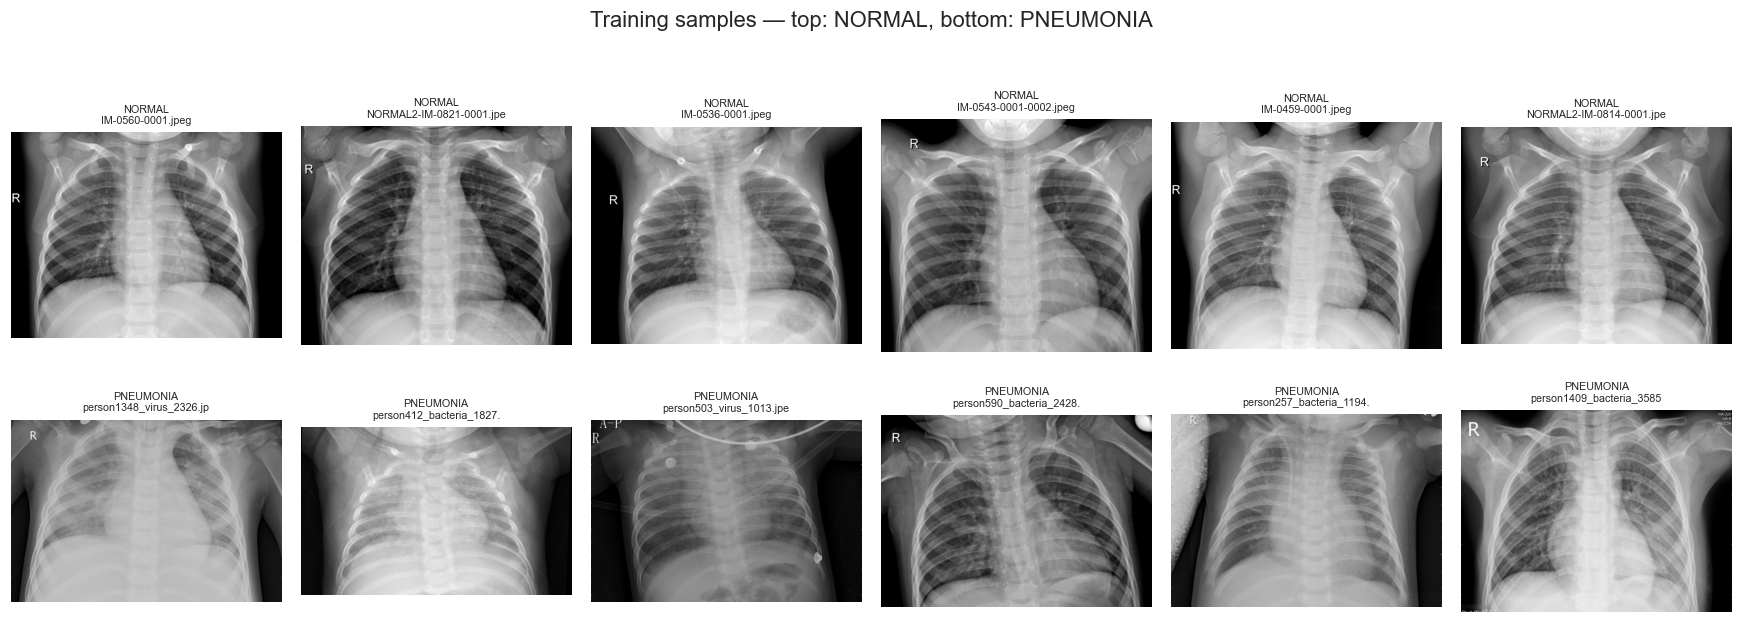

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
rng = np.random.default_rng(SEED)
for r, cls in enumerate(CLASSES):
    sample = files.query("split == 'train' and cls == @cls").sample(6, random_state=SEED)
    for ax, (_, row) in zip(axes[r], sample.iterrows()):
        ax.imshow(Image.open(row["path"]).convert("L"), cmap="gray")
        ax.set_title(f"{cls}\n{row['filename'][:24]}", fontsize=7)
        ax.axis("off")
fig.suptitle("Training samples — top: NORMAL, bottom: PNEUMONIA", y=1.02)
fig.tight_layout()
save_fig("01_sample_images")
plt.show()

Even by eye the pneumonia images show the expected pattern — hazy white opacity in the lung
fields, where the normal images have darker, better-defined lung space. The images vary a lot in
framing, contrast and rotation, and several include arm bones or text markers at the edges. That
variability is an argument for augmentation rather than against it.

        width  height  aspect
count   400.0   400.0   400.0
mean   1337.3   983.4     1.4
std     356.4   375.1     0.2
min     415.0   211.0     0.9
25%    1070.0   688.0     1.3
50%    1272.0   899.5     1.4
75%    1570.0  1200.5     1.6
max    2444.0  2183.0     2.3

colour modes in sample: {'RGB': 2, 'L': 148}


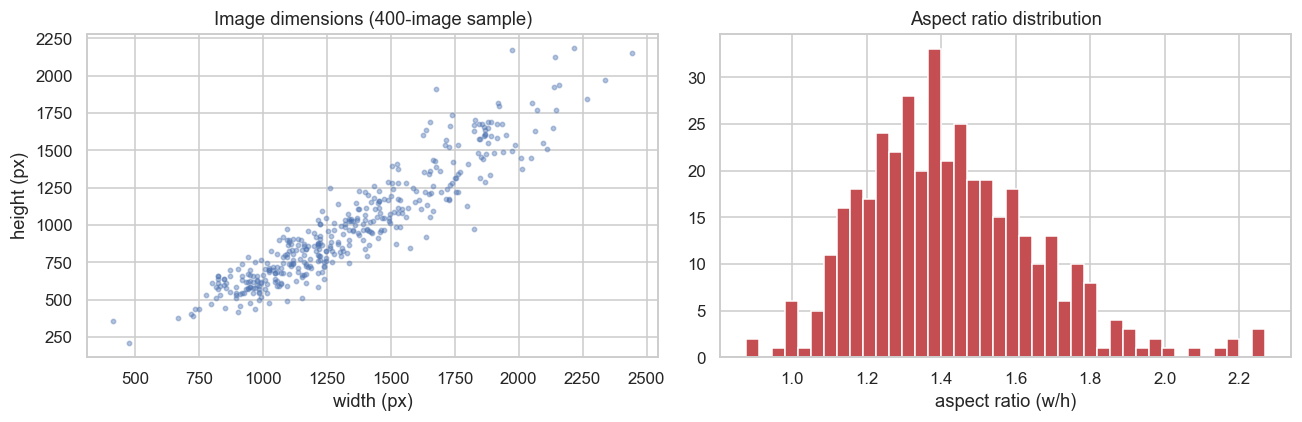

In [7]:
sample = files.sample(400, random_state=SEED)
dims = np.array([Image.open(p).size for p in sample["path"]])
size_df = pd.DataFrame(dims, columns=["width", "height"])
size_df["aspect"] = size_df["width"] / size_df["height"]
print(size_df.describe().round(1).to_string())

modes = Counter(Image.open(p).mode for p in sample["path"][:150])
print("\ncolour modes in sample:", dict(modes))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(size_df["width"], size_df["height"], s=8, alpha=0.4, color=NORMAL_COLOR)
axes[0].set(xlabel="width (px)", ylabel="height (px)", title="Image dimensions (400-image sample)")
axes[1].hist(size_df["aspect"], bins=40, color=PNEU_COLOR)
axes[1].set(xlabel="aspect ratio (w/h)", title="Aspect ratio distribution")
fig.tight_layout()
save_fig("02_image_dimensions")
plt.show()

Image sizes are all over the place — from roughly 384px to over 2900px wide — so everything has
to be resized to a common input. A few files are stored as RGB even though the content is
greyscale, so I convert every image to single-channel `L` on load.

**Resolution choice: 180×180 greyscale.** Consolidation in a chest X-ray is a large, diffuse
feature, not fine texture, so it survives aggressive downsampling. 180px keeps the whole dataset
in memory as `uint8` (about 190 MB) while remaining large enough for four pooling stages.

## 4. Loading, caching and splitting

Decoding 5,800 JPEGs takes about 25 seconds and would otherwise be repeated every epoch. Since
the resized dataset is only ~190 MB, I decode once into a `uint8` array and cache it to disk.
Training then reads from memory, which removes disk I/O and JPEG decoding from the training loop
entirely — and it is why `num_workers=0` is fine here (it also sidesteps the multiprocessing
fork problems DataLoader workers cause on macOS).

In [8]:
def load_images(frame, size=IMG_SIZE):
    """Decode, greyscale and resize every image in `frame` into one uint8 array."""
    out = np.zeros((len(frame), size, size), dtype=np.uint8)
    for i, path in enumerate(frame["path"]):
        img = Image.open(path).convert("L").resize((size, size), Image.BILINEAR)
        out[i] = np.asarray(img)
    return out

cache_file = CACHE_DIR / f"images_{IMG_SIZE}.npy"
manifest_file = CACHE_DIR / f"manifest_{IMG_SIZE}.csv"

if cache_file.exists() and manifest_file.exists() and len(pd.read_csv(manifest_file)) == len(files):
    images = np.load(cache_file)
    print(f"loaded cached array {images.shape} ({images.nbytes / 1e6:.0f} MB)")
else:
    t0 = time.time()
    images = load_images(files)
    np.save(cache_file, images)
    files[["filename", "split", "cls", "label", "patient", "pathogen"]].to_csv(manifest_file, index=False)
    print(f"decoded {len(files):,} images in {time.time() - t0:.1f}s "
          f"-> {images.nbytes / 1e6:.0f} MB")

labels = files["label"].to_numpy()

loaded cached array (5824, 180, 180) (189 MB)


In [9]:
# Official train + val form the pool I am allowed to learn from; test is untouched until the end.
pool_mask = files["split"].isin(["train", "val"]).to_numpy()
pool_idx = np.where(pool_mask)[0]
test_idx = np.where(files["split"].to_numpy() == "test")[0]

# StratifiedGroupKFold keeps the class ratio steady while guaranteeing that no patient's images
# are split across the two sides.
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
train_rel, val_rel = next(sgkf.split(
    X=np.zeros(len(pool_idx)),
    y=labels[pool_idx],
    groups=files["patient"].to_numpy()[pool_idx],
))
train_idx, val_idx = pool_idx[train_rel], pool_idx[val_rel]

def describe(name, idx):
    lab = labels[idx]
    pats = set(files["patient"].to_numpy()[idx])
    print(f"{name:<6} {len(idx):>5,} images  {len(pats):>5,} patients  "
          f"pneumonia {100 * lab.mean():5.1f}%")
    return pats

p_tr = describe("train", train_idx)
p_va = describe("val", val_idx)
p_te = describe("test", test_idx)
print(f"\npatient overlap train ∩ val: {len(p_tr & p_va)}  (must be 0)")
assert len(p_tr & p_va) == 0

train  4,647 images  2,575 patients  pneumonia  73.8%
val      559 images    286 patients  pneumonia  76.6%
test     618 images    426 patients  pneumonia  62.6%

patient overlap train ∩ val: 0  (must be 0)


Zero patient overlap between train and validation, and the class ratio is preserved on both
sides. The validation set now has ~580 images instead of 16, which is enough to make early
stopping and threshold selection meaningful.

## 5. Normalisation and augmentation

In [10]:
# Normalisation statistics come from the training split only — computing them over the whole
# dataset would leak test information into preprocessing.
train_pixels = images[train_idx].astype(np.float32) / 255.0
MEAN, STD = float(train_pixels.mean()), float(train_pixels.std())
del train_pixels
print(f"train pixel mean {MEAN:.4f}, std {STD:.4f}")

train pixel mean 0.4828, std 0.2363


### Choosing augmentations for chest radiographs

Augmentation has to respect what the images actually are. My choices, and the reasoning:

| Transform | Used | Why |
|---|---|---|
| Rotation ±8°, translate 6%, scale 0.9–1.1 | **yes** | Real patient positioning varies this much between shots |
| Brightness / contrast jitter ±15% | **yes** | X-ray exposure settings differ between machines and operators |
| Horizontal flip | **no** | A mirrored chest X-ray is anatomically impossible — the heart sits left. Flipping teaches the network to accept images it will never see, and destroys the left/right asymmetry a radiologist relies on |
| Vertical flip / large rotation | **no** | Same reason, more so |
| Random crop | **light only** | Consolidation can sit at the lung periphery; an aggressive crop can remove the finding while keeping the label |

The horizontal-flip decision is the one worth stating explicitly, because `RandomHorizontalFlip`
is in almost every image-classification tutorial and is wrong for this modality.

In [11]:
train_tf = v2.Compose([
    v2.RandomAffine(degrees=8, translate=(0.06, 0.06), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.15, contrast=0.15),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[MEAN], std=[STD]),
])

eval_tf = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[MEAN], std=[STD]),
])

class XRayDataset(Dataset):
    """Serves images from the pre-decoded in-memory array."""

    def __init__(self, array, labels, indices, transform):
        self.array, self.labels, self.indices, self.transform = array, labels, indices, transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        img = torch.from_numpy(self.array[j]).unsqueeze(0)   # (1, H, W) uint8
        return self.transform(img), torch.tensor(self.labels[j], dtype=torch.float32)

BATCH_SIZE = 64
train_ds = XRayDataset(images, labels, train_idx, train_tf)
val_ds = XRayDataset(images, labels, val_idx, eval_tf)
test_ds = XRayDataset(images, labels, test_idx, eval_tf)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"batches per epoch: train {len(train_dl)}, val {len(val_dl)}, test {len(test_dl)}")

batches per epoch: train 72, val 9, test 10


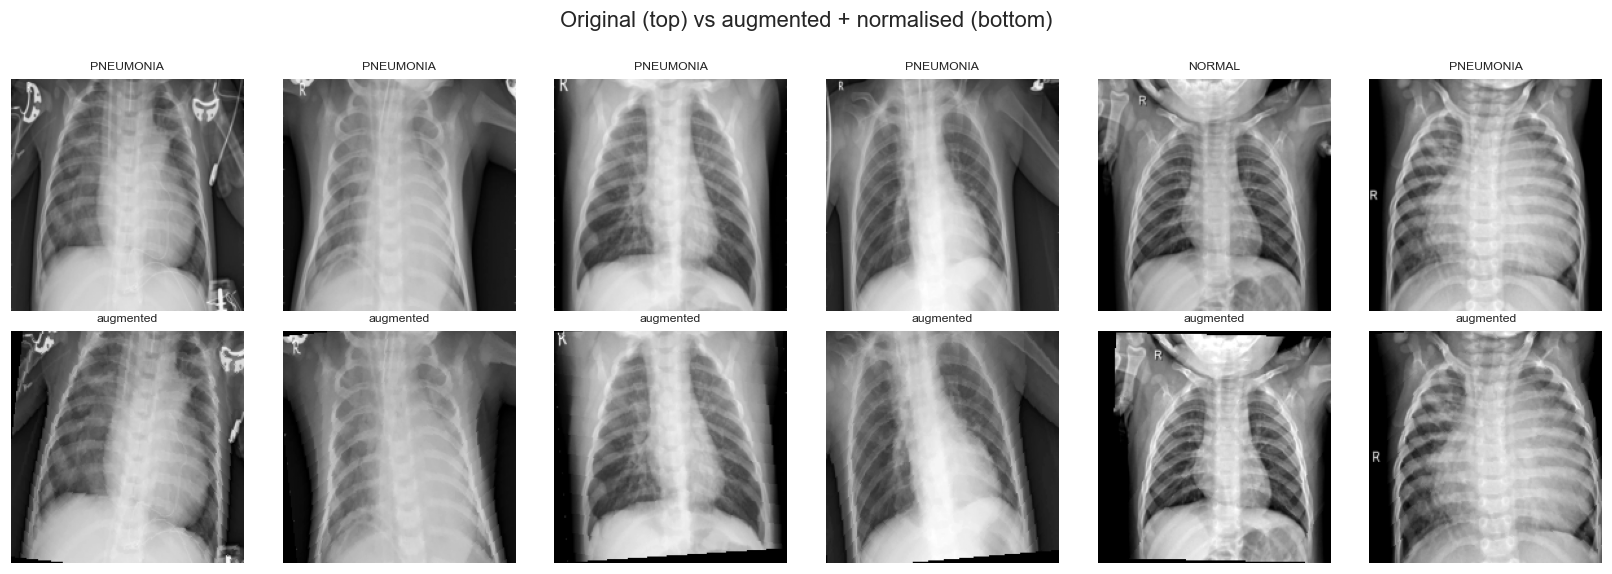

In [12]:
# Sanity check: what the network actually receives after augmentation.
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
demo_idx = [int(i) for i in np.random.default_rng(0).choice(len(train_ds), 6, replace=False)]
for col, di in enumerate(demo_idx):
    raw = images[train_idx[di]]
    axes[0, col].imshow(raw, cmap="gray")
    axes[0, col].set_title(CLASSES[labels[train_idx[di]]], fontsize=8)
    aug = train_ds[di][0].squeeze(0).numpy()
    axes[1, col].imshow(aug, cmap="gray")
    axes[1, col].set_title("augmented", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Original (top) vs augmented + normalised (bottom)", y=1.0)
fig.tight_layout()
save_fig("03_augmentation")
plt.show()

## 6. The CNN

The architecture is a compact VGG-style stack: four blocks of `Conv-BN-ReLU ×2` followed by
max-pooling, doubling the channel count each time (32 → 64 → 128 → 256) as the spatial size
halves (180 → 90 → 45 → 22 → 11).

Design decisions worth justifying:

- **Batch normalisation after every convolution.** X-ray exposure varies widely between images;
  BN stabilises the activation scale and let me train at a higher learning rate.
- **Two 3×3 convolutions per block** rather than one 5×5. Same receptive field, fewer parameters,
  one extra non-linearity.
- **Global average pooling instead of `Flatten` + a large dense layer.** A flattened 11×11×256
  feature map into a 512-unit dense layer would be ~16M parameters — the overwhelming majority of
  the network, and the part most likely to memorise 5,000 images. GAP removes it entirely and
  keeps the model at ~1.2M parameters.
- **A single logit output** with `BCEWithLogitsLoss`, which is numerically safer than a sigmoid
  followed by BCE and accepts the `pos_weight` argument used below.

In [13]:
class PneumoniaCNN(nn.Module):
    def __init__(self, dropout=0.4):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1, bias=False),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            block(1, 32), block(32, 64), block(64, 128), block(128, 256)
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


model = PneumoniaCNN().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\ntrainable parameters: {n_params:,}")
with torch.no_grad():
    dummy = torch.zeros(2, 1, IMG_SIZE, IMG_SIZE, device=DEVICE)
    print("output shape:", tuple(model(dummy).shape))

PneumoniaCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2,

### Handling the class imbalance

The training split is about 74% pneumonia. `BCEWithLogitsLoss(pos_weight=...)` scales the loss
contribution of the positive class; setting it to `n_negative / n_positive` makes the two classes
contribute equally.

Here that ratio is below 1, which pushes the model *away* from its majority-class bias — the
opposite direction to the bank problem in Problem Set 02, but the same underlying correction.

In [14]:
n_pos = int(labels[train_idx].sum())
n_neg = len(train_idx) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], device=DEVICE)
print(f"train: {n_neg:,} normal / {n_pos:,} pneumonia  ->  pos_weight = {pos_weight.item():.3f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

train: 1,217 normal / 3,430 pneumonia  ->  pos_weight = 0.355


## 7. Training

In [15]:
@torch.no_grad()
def predict(net, loader):
    """Return (probabilities, targets) for a whole loader."""
    net.eval()
    probs, targets = [], []
    for x, y in loader:
        logits = net(x.to(DEVICE)).squeeze(1)
        probs.append(torch.sigmoid(logits).cpu())
        targets.append(y)
    return torch.cat(probs).numpy(), torch.cat(targets).numpy().astype(int)


def run_epoch(net, loader, optim):
    net.train()
    total_loss, correct, seen = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optim.zero_grad()
        logits = net(x).squeeze(1)
        loss = criterion(logits, y)
        loss.backward()
        optim.step()
        total_loss += loss.item() * len(y)
        correct += ((logits > 0).float() == y).sum().item()
        seen += len(y)
    return total_loss / seen, correct / seen

In [16]:
EPOCHS = 35
PATIENCE = 8           # epochs without validation-AUC improvement before stopping
BEST_PATH = MODEL_DIR / "pneumonia_cnn.pt"

history = []
best_auc, best_epoch, stale = -np.inf, -1, 0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = run_epoch(model, train_dl, optimizer)

    val_probs, val_true = predict(model, val_dl)
    val_loss = F.binary_cross_entropy(torch.tensor(val_probs),
                                      torch.tensor(val_true, dtype=torch.float32)).item()
    val_auc = roc_auc_score(val_true, val_probs)
    val_acc = accuracy_score(val_true, val_probs >= 0.5)
    val_recall = recall_score(val_true, val_probs >= 0.5)

    scheduler.step(val_auc)
    history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                    "val_loss": val_loss, "val_acc": val_acc, "val_auc": val_auc,
                    "val_recall": val_recall, "lr": optimizer.param_groups[0]["lr"],
                    "seconds": time.time() - t0})

    # Model selection on validation AUC: it is threshold-free, so it is not distorted by the
    # class imbalance the way raw accuracy is.
    flag = ""
    if val_auc > best_auc:
        best_auc, best_epoch, stale = val_auc, epoch, 0
        torch.save(model.state_dict(), BEST_PATH)
        flag = "  <- best"
    else:
        stale += 1

    print(f"epoch {epoch:2d}/{EPOCHS}  loss {train_loss:.4f}  acc {train_acc:.4f}  |  "
          f"val loss {val_loss:.4f}  acc {val_acc:.4f}  auc {val_auc:.4f}  "
          f"recall {val_recall:.4f}  ({time.time() - t0:.0f}s){flag}")

    if stale >= PATIENCE:
        print(f"\nno validation improvement for {PATIENCE} epochs - stopping early")
        break

print(f"\ntotal training time: {(time.time() - t_start) / 60:.1f} min")
print(f"best epoch: {best_epoch} (val AUC {best_auc:.4f})")
model.load_state_dict(torch.load(BEST_PATH))

epoch  1/35  loss 0.1781  acc 0.8414  |  val loss 0.9355  acc 0.7030  auc 0.9642  recall 0.6121  (26s)  <- best


epoch  2/35  loss 0.1226  acc 0.9047  |  val loss 0.2263  acc 0.8837  auc 0.9898  recall 1.0000  (26s)  <- best


epoch  3/35  loss 0.0957  acc 0.9219  |  val loss 0.1229  acc 0.9481  auc 0.9882  recall 0.9696  (25s)


epoch  4/35  loss 0.0879  acc 0.9310  |  val loss 0.3230  acc 0.8623  auc 0.9898  recall 1.0000  (25s)


epoch  5/35  loss 0.0769  acc 0.9399  |  val loss 0.1670  acc 0.9320  auc 0.9925  recall 1.0000  (25s)  <- best


epoch  6/35  loss 0.0616  acc 0.9542  |  val loss 0.5928  acc 0.8050  auc 0.9900  recall 0.7453  (25s)


... (26 outputs left out)

epoch 33/35  loss 0.0182  acc 0.9876  |  val loss 0.0553  acc 0.9839  auc 0.9988  recall 0.9790  (25s)


epoch 34/35  loss 0.0149  acc 0.9896  |  val loss 0.0585  acc 0.9785  auc 0.9987  recall 0.9720  (25s)


epoch 35/35  loss 0.0162  acc 0.9909  |  val loss 0.0790  acc 0.9732  auc 0.9985  recall 0.9650  (25s)

total training time: 14.5 min
best epoch: 32 (val AUC 0.9989)


<All keys matched successfully>

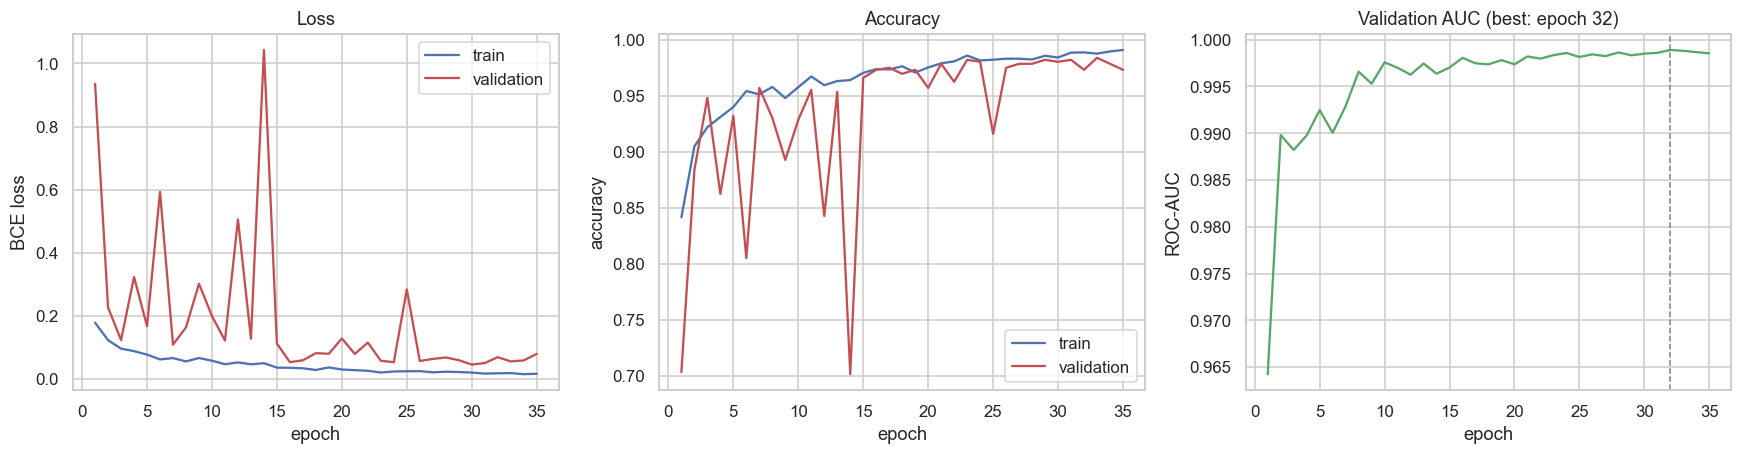

In [17]:
hist = pd.DataFrame(history)
hist.to_csv(RESULT_DIR / "training_history.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train", color=NORMAL_COLOR)
axes[0].plot(hist["epoch"], hist["val_loss"], label="validation", color=PNEU_COLOR)
axes[0].set(xlabel="epoch", ylabel="BCE loss", title="Loss")

axes[1].plot(hist["epoch"], hist["train_acc"], label="train", color=NORMAL_COLOR)
axes[1].plot(hist["epoch"], hist["val_acc"], label="validation", color=PNEU_COLOR)
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")

axes[2].plot(hist["epoch"], hist["val_auc"], color="#55A868")
axes[2].axvline(best_epoch, ls="--", color="grey", lw=1)
axes[2].set(xlabel="epoch", ylabel="ROC-AUC", title=f"Validation AUC (best: epoch {best_epoch})")

for ax in axes[:2]:
    ax.legend()
fig.tight_layout()
save_fig("04_training_curves")
plt.show()

## 8. Choosing the decision threshold — on validation, not test

The default 0.5 cut-off assumes false positives and false negatives cost the same, which is not
true for a screening test. I pick the threshold on the **validation** set and then apply it to
the test set exactly once.

Two candidate operating points:

- **F1-optimal** — the balanced choice.
- **High-recall** — targeting ≥98% recall on validation. Since recall falls monotonically as the
  threshold rises, the thresholds meeting that target form a range starting at zero; I take the
  **highest** one, which is the point that hits the recall target while giving up the least
  specificity. (Taking the lowest instead would technically satisfy the target while classifying
  almost everything as pneumonia — a degenerate operating point.)

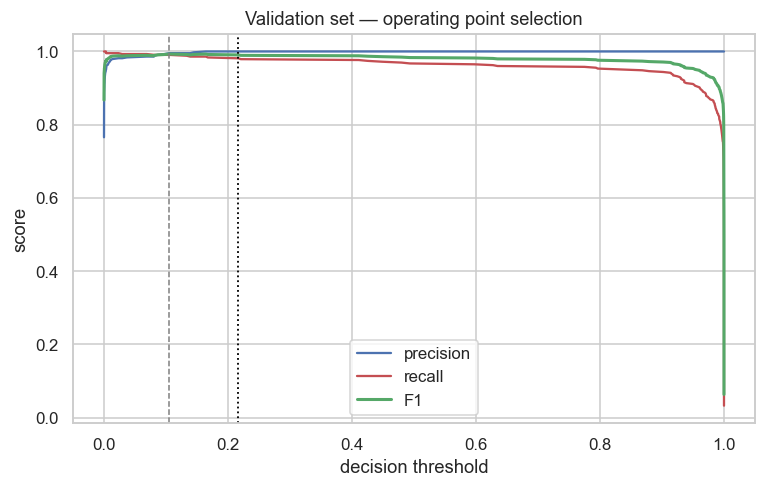

validation AUC        : 0.9989

default      thr 0.500  recall 0.9650  precision 1.0000  specificity 1.0000  F1 0.9822
F1-optimal   thr 0.105  recall 0.9907  precision 0.9953  specificity 0.9847  F1 0.9930
high-recall  thr 0.217  recall 0.9813  precision 1.0000  specificity 1.0000  F1 0.9906


In [18]:
val_probs, val_true = predict(model, val_dl)

prec, rec, thr = precision_recall_curve(val_true, val_probs)
f1_curve = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
best_f1_idx = int(np.argmax(f1_curve[:-1]))
thr_f1 = float(thr[best_f1_idx])

# Highest threshold that still reaches >=98% recall on validation. Recall decreases as the
# threshold rises, so the qualifying thresholds run from 0 up to some maximum - and that
# maximum is the one that costs the least specificity.
TARGET_RECALL = 0.98
ok = rec[:-1] >= TARGET_RECALL
thr_recall = float(thr[ok][-1]) if ok.any() else thr_f1

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(thr, prec[:-1], label="precision", color=NORMAL_COLOR)
ax.plot(thr, rec[:-1], label="recall", color=PNEU_COLOR)
ax.plot(thr, f1_curve[:-1], label="F1", color="#55A868", lw=2)
ax.axvline(thr_f1, ls="--", color="grey", lw=1)
ax.axvline(thr_recall, ls=":", color="black", lw=1.2)
ax.set(xlabel="decision threshold", ylabel="score",
       title="Validation set — operating point selection")
ax.legend()
save_fig("05_threshold_selection")
plt.show()

print(f"validation AUC        : {roc_auc_score(val_true, val_probs):.4f}\n")
for name, t in [("default", 0.5), ("F1-optimal", thr_f1), ("high-recall", thr_recall)]:
    pred = val_probs >= t
    print(f"{name:<12} thr {t:.3f}  "
          f"recall {recall_score(val_true, pred):.4f}  "
          f"precision {precision_score(val_true, pred):.4f}  "
          f"specificity {recall_score(val_true, pred, pos_label=0):.4f}  "
          f"F1 {f1_score(val_true, pred):.4f}")

## 9. Final evaluation on the held-out test set

In [19]:
test_probs, test_true = predict(model, test_dl)

def metrics_at(threshold):
    pred = (test_probs >= threshold).astype(int)
    return {
        "threshold": round(float(threshold), 4),
        "accuracy": accuracy_score(test_true, pred),
        "precision": precision_score(test_true, pred),
        "recall": recall_score(test_true, pred),
        "specificity": recall_score(test_true, pred, pos_label=0),
        "f1": f1_score(test_true, pred),
        "roc_auc": roc_auc_score(test_true, test_probs),
        "pr_auc": average_precision_score(test_true, test_probs),
    }

results = pd.DataFrame({
    "default (0.50)": metrics_at(0.5),
    f"F1-optimal ({thr_f1:.2f})": metrics_at(thr_f1),
    f"high-recall ({thr_recall:.2f})": metrics_at(thr_recall),
}).T.round(4)
results

,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
default (0.50),0.5000,0.9045,0.8744,0.9897,0.7619,0.9285,0.9701,0.9775
F1-optimal (0.10),0.1050,0.8576,0.8161,0.9974,0.6234,0.8977,0.9701,0.9775
high-recall (0.22),0.2168,0.8786,0.8406,0.9948,0.6840,0.9112,0.9701,0.9775


              precision    recall  f1-score   support

      NORMAL     0.9875    0.6840    0.8082       231
   PNEUMONIA     0.8406    0.9948    0.9112       387

    accuracy                         0.8786       618
   macro avg     0.9141    0.8394    0.8597       618
weighted avg     0.8955    0.8786    0.8727       618



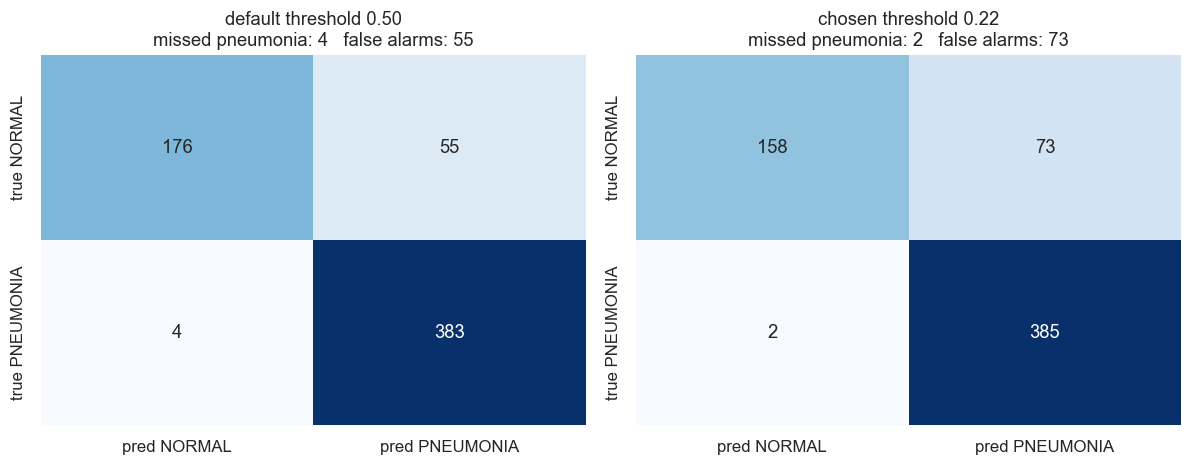

In [20]:
CHOSEN_THR = thr_recall
test_pred = (test_probs >= CHOSEN_THR).astype(int)

print(classification_report(test_true, test_pred, target_names=CLASSES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, t, title in [(axes[0], 0.5, "default threshold 0.50"),
                     (axes[1], CHOSEN_THR, f"chosen threshold {CHOSEN_THR:.2f}")]:
    cm = confusion_matrix(test_true, (test_probs >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=[f"pred {c}" for c in CLASSES],
                yticklabels=[f"true {c}" for c in CLASSES])
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{title}\nmissed pneumonia: {fn}   false alarms: {fp}")
fig.tight_layout()
save_fig("06_confusion_matrices")
plt.show()

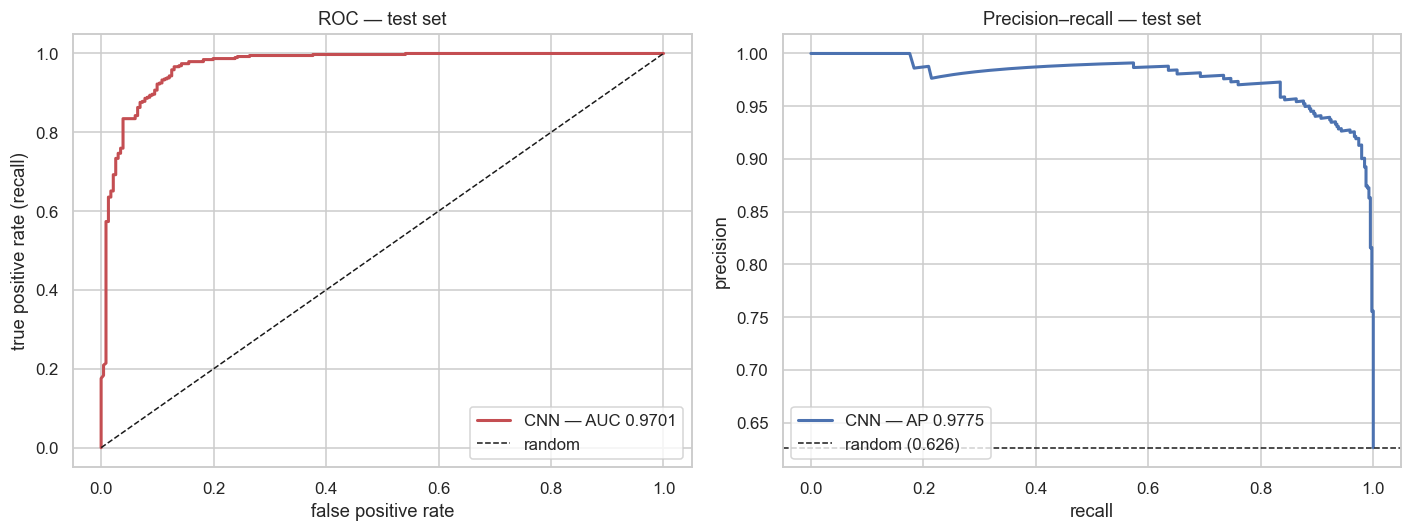

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fpr, tpr, _ = roc_curve(test_true, test_probs)
axes[0].plot(fpr, tpr, color=PNEU_COLOR, lw=2,
             label=f"CNN — AUC {roc_auc_score(test_true, test_probs):.4f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC — test set")
axes[0].legend(loc="lower right")

p_t, r_t, _ = precision_recall_curve(test_true, test_probs)
axes[1].plot(r_t, p_t, color=NORMAL_COLOR, lw=2,
             label=f"CNN — AP {average_precision_score(test_true, test_probs):.4f}")
axes[1].axhline(test_true.mean(), ls="--", color="k", lw=1,
                label=f"random ({test_true.mean():.3f})")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision–recall — test set")
axes[1].legend(loc="lower left")
fig.tight_layout()
save_fig("07_roc_pr_curves")
plt.show()

## 10. Validation vs test — where the model actually loses accuracy

The validation AUC (see above) is far higher than the test AUC. That gap deserves an explanation
rather than a shrug, so this section compares the two sets directly at the same threshold.

In [22]:
gap_rows = []
for name, probs, truth in [("validation", val_probs, val_true), ("test", test_probs, test_true)]:
    pred = (probs >= CHOSEN_THR).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, pred).ravel()
    gap_rows.append({
        "set": name, "n": len(truth), "pneumonia_%": round(100 * truth.mean(), 1),
        "roc_auc": round(roc_auc_score(truth, probs), 4),
        "recall": round(recall_score(truth, pred), 4),
        "specificity": round(recall_score(truth, pred, pos_label=0), 4),
        "missed": int(fn), "false_alarms": int(fp),
    })
gap = pd.DataFrame(gap_rows).set_index("set")
gap

,n,pneumonia_%,roc_auc,recall,specificity,missed,false_alarms
set,,,,,,,
validation,559,76.6,0.9989,0.9813,1.000,8,0
test,618,62.6,0.9701,0.9948,0.684,2,73


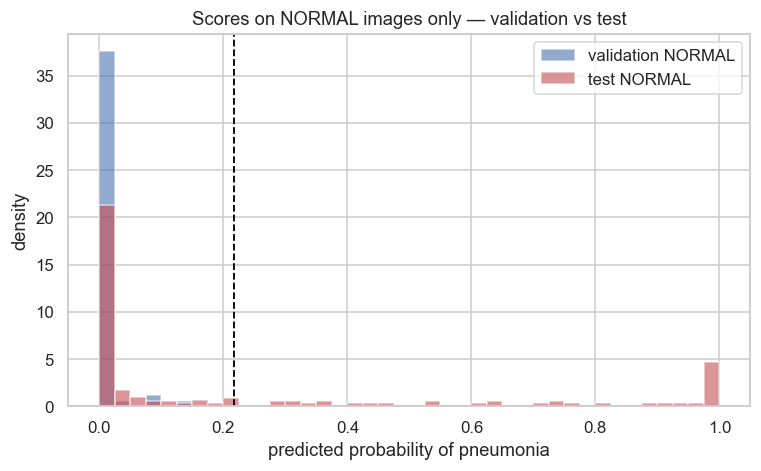

validation NORMAL images scoring >0.5: 0 of 131
test NORMAL images scoring >0.5      : 55 of 231


In [23]:
fig, ax = plt.subplots(figsize=(8, 4.4))
bins = np.linspace(0, 1, 41)
ax.hist(val_probs[val_true == 0], bins=bins, alpha=0.6, density=True,
        color=NORMAL_COLOR, label="validation NORMAL")
ax.hist(test_probs[test_true == 0], bins=bins, alpha=0.6, density=True,
        color=PNEU_COLOR, label="test NORMAL")
ax.axvline(CHOSEN_THR, ls="--", color="black", lw=1.2)
ax.set(xlabel="predicted probability of pneumonia", ylabel="density",
       title="Scores on NORMAL images only — validation vs test")
ax.legend()
save_fig("08_val_vs_test_normals")
plt.show()

print(f"validation NORMAL images scoring >0.5: "
      f"{(val_probs[val_true == 0] > 0.5).sum()} of {(val_true == 0).sum()}")
print(f"test NORMAL images scoring >0.5      : "
      f"{(test_probs[test_true == 0] > 0.5).sum()} of {(test_true == 0).sum()}")

**Recall generalises; specificity does not.** The model finds pneumonia just as reliably on the
test set as on validation, but it raises far more false alarms on the test set's NORMAL images
than on validation's.

The most likely explanation is that my validation split is carved out of the official *training*
folder, so it shares that folder's acquisition characteristics — same equipment, same time
window, same operators. The official test folder appears to be a separate batch. Patient-grouped
splitting removed patient leakage, but it cannot remove *batch* similarity, because there is only
one batch available to split.

This is worth stating plainly: **validation AUC overstates real-world performance here**, and the
test set is the only honest estimate. It is also the reason the validation-selected threshold
does not transfer perfectly — the score distributions it was tuned on are not the ones it meets
at test time.

## 11. Error analysis

The aggregate numbers hide the interesting question: *which* cases does the model get wrong?
The filenames record whether each pneumonia case is bacterial or viral, which allows a breakdown
the plain confusion matrix cannot give. Bacterial pneumonia typically shows dense lobar
consolidation while viral pneumonia produces a subtler, more diffuse interstitial pattern, so the
usual expectation is that viral cases are harder.

In [24]:
test_files = files.iloc[test_idx].copy().reset_index(drop=True)
test_files["prob"] = test_probs
test_files["pred"] = test_pred
test_files["correct"] = test_files["pred"] == test_files["label"]

breakdown = (
    test_files.groupby(["cls", "pathogen"])
    .agg(n=("correct", "size"), correct=("correct", "sum"),
         mean_prob=("prob", "mean"))
    .assign(accuracy=lambda t: (t["correct"] / t["n"]).round(4),
            mean_prob=lambda t: t["mean_prob"].round(3))
    .drop(columns="correct")
)
breakdown

n  mean_prob  accuracy
cls       pathogen                           
NORMAL    none       231      0.254    0.6840
PNEUMONIA bacterial  240      0.987    0.9917
          viral      147      0.980    1.0000

**This is not the result I expected.** The usual assumption — the one I stated above — is that
viral pneumonia should be harder, because its diffuse interstitial pattern is subtler than
bacterial lobar consolidation. It is not what happened: viral cases were caught at **100%**
(147/147) and bacterial at **99.2%** (238/240). The pathogen distinction makes no practical
difference to this model.

The real weakness is on the other side of the confusion matrix. Every meaningful error is a
**false alarm on a NORMAL image** — 73 of them against just 2 missed pneumonia cases. The mean
predicted probability tells the same story: 0.987 for bacterial and 0.980 for viral pneumonia
against 0.254 for normal, so the pneumonia class is separated cleanly and it is the normal class
that spreads across the range.

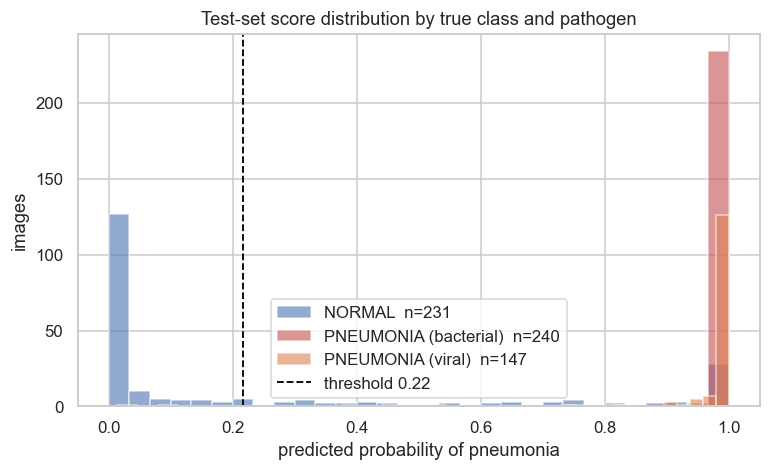

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for grp_name, color in [("none", NORMAL_COLOR), ("bacterial", "#C44E52"), ("viral", "#DD8452")]:
    sub = test_files.query("pathogen == @grp_name")
    if len(sub):
        label = "NORMAL" if grp_name == "none" else f"PNEUMONIA ({grp_name})"
        ax.hist(sub["prob"], bins=30, alpha=0.6, label=f"{label}  n={len(sub)}", color=color)
ax.axvline(CHOSEN_THR, ls="--", color="black", lw=1.2, label=f"threshold {CHOSEN_THR:.2f}")
ax.set(xlabel="predicted probability of pneumonia", ylabel="images",
       title="Test-set score distribution by true class and pathogen")
ax.legend()
save_fig("09_score_distribution")
plt.show()

missed pneumonia (false negatives): 2
false alarms (false positives)    : 73


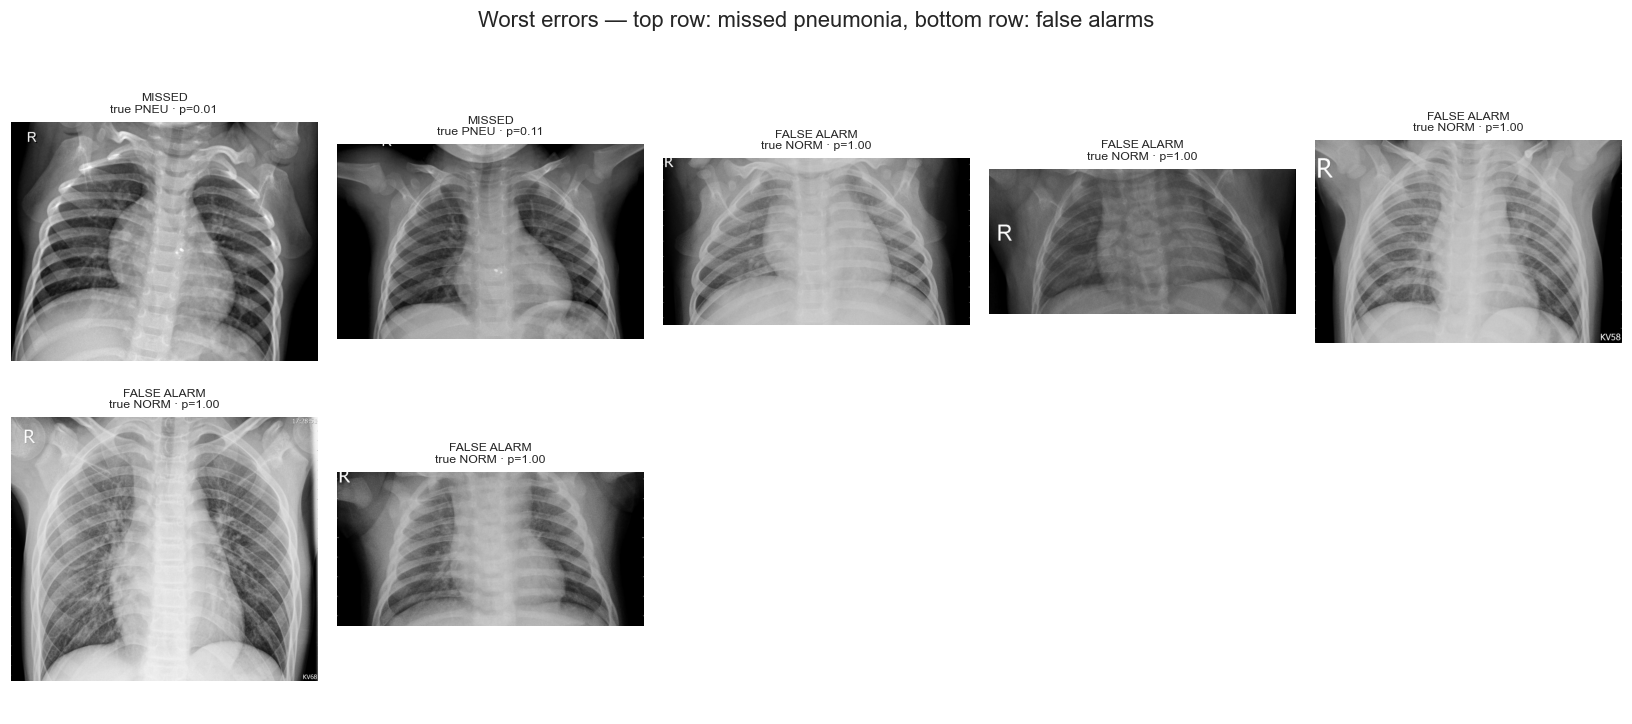

In [26]:
errors = test_files.query("~correct").sort_values("prob")
fn = errors.query("label == 1")   # missed pneumonia
fp = errors.query("label == 0")   # false alarms
print(f"missed pneumonia (false negatives): {len(fn)}")
print(f"false alarms (false positives)    : {len(fp)}")

show = pd.concat([fn.head(5), fp.tail(5)])
if len(show):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
    for ax, (_, row) in zip(axes.ravel(), show.iterrows()):
        ax.imshow(Image.open(row["path"]).convert("L"), cmap="gray")
        kind = "MISSED" if row["label"] == 1 else "FALSE ALARM"
        ax.set_title(f"{kind}\ntrue {row['cls'][:4]} · p={row['prob']:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes.ravel()[len(show):]:
        ax.axis("off")
    fig.suptitle("Worst errors — top row: missed pneumonia, bottom row: false alarms", y=1.01)
    fig.tight_layout()
    save_fig("10_misclassified")
    plt.show()

**The false alarms are not all borderline.** Of the 73 false positives, **33 score above 0.90 and
21 above 0.99** — the model is confidently wrong on a substantial minority of normal chest X-rays,
not merely undecided. The two missed pneumonia cases, by contrast, scored 0.11 and 0.01.

That asymmetry matters for how the model would be deployed. A confident false positive cannot be
filtered out by raising the threshold, because it sits at the very top of the score range. It
would have to be caught by a human reading the image.

## 12. Grad-CAM — is the model looking at the lungs?

A CNN can reach a good score for the wrong reason: text markers, image borders, or scanner
artefacts that happen to correlate with the class. Grad-CAM weights the final convolutional
feature maps by the gradient of the output with respect to them, producing a heat map of the
regions that drove the prediction. If the model is genuinely reading lung opacity, the heat
should sit over the lung fields.

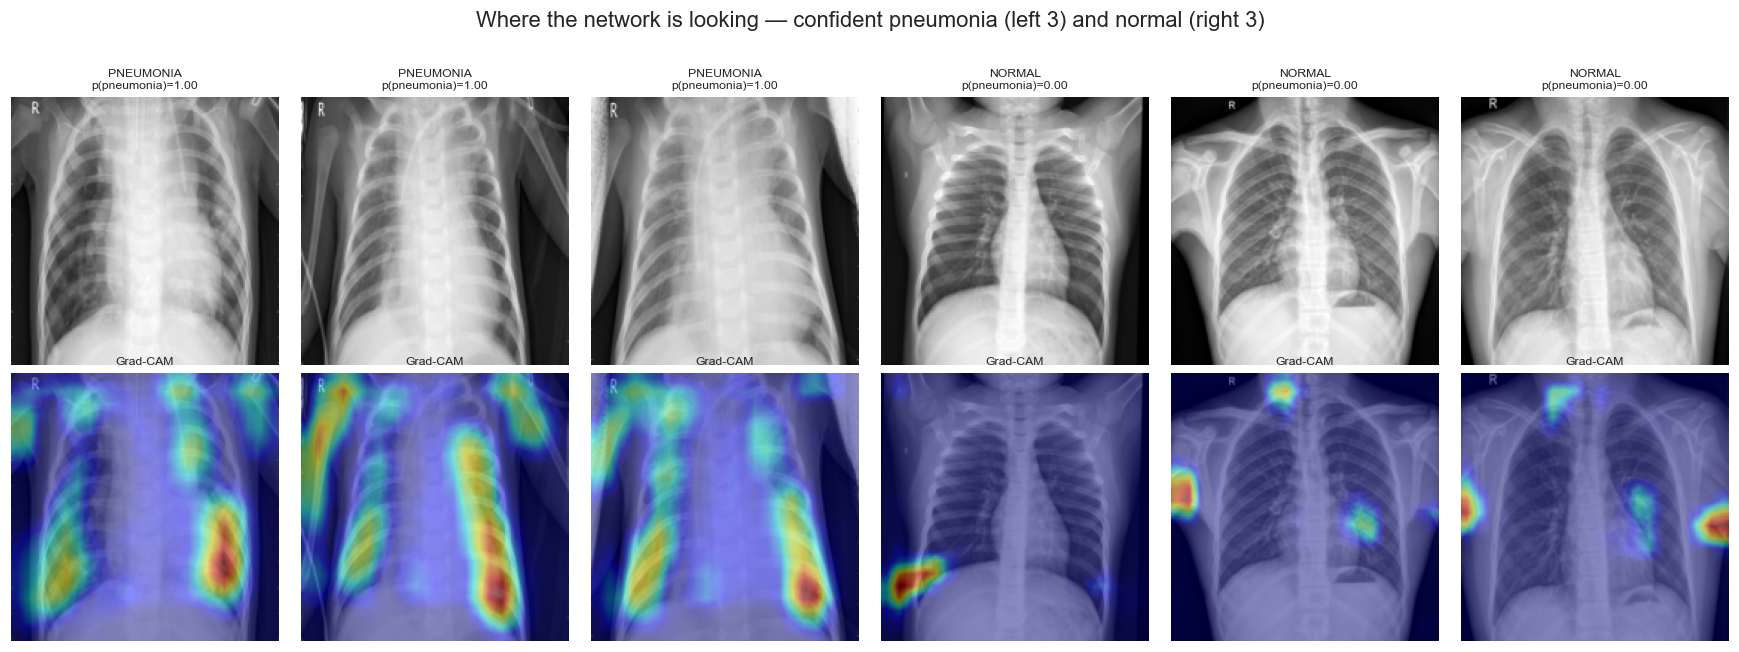

In [27]:
class GradCAM:
    """Grad-CAM over the last convolutional block."""

    def __init__(self, net, target_layer):
        self.net = net
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x):
        self.net.eval()
        self.net.zero_grad()
        logit = self.net(x).squeeze()
        logit.backward()
        # One weight per channel: the mean gradient flowing into that feature map.
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())
        return cam, torch.sigmoid(logit).item()


cam_engine = GradCAM(model, model.features[-1][-2])   # last ReLU of the final conv block

picks = pd.concat([
    test_files.query("label == 1 and correct").nlargest(3, "prob"),
    test_files.query("label == 0 and correct").nsmallest(3, "prob"),
])

fig, axes = plt.subplots(2, 6, figsize=(16, 5.8))
for col, (_, row) in enumerate(picks.iterrows()):
    j = test_idx[row.name]
    tensor = eval_tf(torch.from_numpy(images[j]).unsqueeze(0)).unsqueeze(0).to(DEVICE)
    cam, prob = cam_engine(tensor)

    axes[0, col].imshow(images[j], cmap="gray")
    axes[0, col].set_title(f"{row['cls']}\np(pneumonia)={prob:.2f}", fontsize=8)
    axes[1, col].imshow(images[j], cmap="gray")
    axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, col].set_title("Grad-CAM", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Where the network is looking — confident pneumonia (left 3) and normal (right 3)", y=1.02)
fig.tight_layout()
save_fig("11_gradcam")
plt.show()

**Reading these honestly:** for the three pneumonia cases (left) the heat sits over the lung
fields — mid and lower zones, which is where consolidation shows — and not on the borders, the
`R` marker or the image edges. That is the reassuring result: the network is using the anatomy
rather than a dataset artefact.

For the three normal cases (right) the maps are scattered and land on the diaphragm and image
edges. That is expected rather than alarming: Grad-CAM here is computed on the *pneumonia* logit,
and on a confidently-normal image there is no positive evidence to localise, so what is left is
essentially noise. These maps should not be over-interpreted — Grad-CAM is informative for the
class the model is predicting, not against it.

## 13. Save the artefacts

In [28]:
final = {
    "device": str(DEVICE),
    "image_size": IMG_SIZE,
    "architecture": "custom 4-block VGG-style CNN",
    "parameters": int(n_params),
    "epochs_run": int(hist["epoch"].max()),
    "best_epoch": int(best_epoch),
    "training_minutes": round(float(hist["seconds"].sum()) / 60, 2),
    "split": {
        "train_images": int(len(train_idx)), "train_patients": len(p_tr),
        "val_images": int(len(val_idx)), "val_patients": len(p_va),
        "test_images": int(len(test_idx)), "test_patients": len(p_te),
        "grouped_by_patient": True,
    },
    "pos_weight": round(float(pos_weight.item()), 4),
    "validation_auc": round(float(best_auc), 4),
    "thresholds": {"f1_optimal": round(thr_f1, 4), "high_recall": round(thr_recall, 4),
                   "chosen": round(float(CHOSEN_THR), 4)},
    "test_metrics": {k: {m: round(float(x), 4) for m, x in v.items()}
                     for k, v in results.T.to_dict().items()},
}
with open(RESULT_DIR / "metrics.json", "w") as f:
    json.dump(final, f, indent=2)

results.to_csv(RESULT_DIR / "test_metrics.csv")
test_files[["filename", "cls", "pathogen", "label", "prob", "pred", "correct"]].to_csv(
    RESULT_DIR / "test_predictions.csv", index=False)

torch.save({"state_dict": model.state_dict(), "image_size": IMG_SIZE,
            "mean": MEAN, "std": STD, "threshold": float(CHOSEN_THR),
            "classes": CLASSES}, MODEL_DIR / "pneumonia_cnn.pt")

print("saved:")
for p in sorted(list(MODEL_DIR.glob("*")) + list(RESULT_DIR.glob("*.csv")) + list(RESULT_DIR.glob("*.json"))):
    print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 1e3:.0f} KB)")
results

saved:
  models/pneumonia_cnn.pt  (4717 KB)
  results/metrics.json  (1 KB)
  results/test_metrics.csv  (0 KB)
  results/test_predictions.csv  (38 KB)
  results/training_history.csv  (5 KB)


,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
default (0.50),0.5000,0.9045,0.8744,0.9897,0.7619,0.9285,0.9701,0.9775
F1-optimal (0.10),0.1050,0.8576,0.8161,0.9974,0.6234,0.8977,0.9701,0.9775
high-recall (0.22),0.2168,0.8786,0.8406,0.9948,0.6840,0.9112,0.9701,0.9775


## 14. Findings

**On the dataset**

- The provided `val` folder holds **16 images**. It is unusable for early stopping or threshold
  selection, so I folded it into the training pool and carved a **559-image** validation set from
  the combined pool instead.
- **Patient identity repeats inside each split** — 1.83 images per patient in the training folder,
  with one patient contributing 30 X-rays and 1,075 of 2,846 patients contributing more than one.
  A random train/validation split would leak the same child across both sides. Splitting by
  patient group is the single most important methodological decision in this notebook.
- A hash check found **30 duplicate image pairs** (32 redundant files), all inside a single split
  and none crossing a split boundary. The official test set is uncontaminated, so the test numbers
  mean what they claim to mean.
- The training set is 74% pneumonia, corrected with `pos_weight = 0.355` in the loss.

**On the model**

- A **1,172,897-parameter** CNN was enough. Replacing the usual `Flatten` + dense head with global
  average pooling removed roughly 16M parameters — the majority of a naive design, and the part
  most prone to memorising 5,000 images.
- **Horizontal flipping was deliberately excluded.** It is standard in natural-image pipelines and
  wrong for chest radiographs, where anatomy is not left-right symmetric.
- Training ran the full 35 epochs (~15 min on the M3 GPU) without early stopping firing; the best
  validation AUC came at epoch 32.

**On the results**

- Test **ROC-AUC 0.9701**, **PR-AUC 0.9775**. At the default 0.5 threshold: accuracy **90.45%**,
  recall **98.97%**, precision 87.44%, specificity 76.19%.
- **The pathogen breakdown contradicted my expectation.** Viral pneumonia was caught at 100%
  (147/147) and bacterial at 99.2% (238/240), despite viral being the radiologically subtler
  pattern. At this resolution the distinction does not matter to the model.
- **Recall generalises; specificity does not.** This is the most important result in the notebook.
  On validation the model reaches AUC 0.9989 with **100% specificity — zero false alarms out of
  131 normal images**. On the official test set specificity collapses to **68.4%**, with 73 false
  alarms out of 231. Pneumonia recall is essentially unchanged (98.1% → 99.5%).
  The likely cause is that my validation split is carved from the official *training* folder and
  therefore shares its acquisition batch, while the test folder is a separate batch. Patient-
  grouped splitting removes patient leakage but cannot remove batch similarity when only one batch
  is available to split. **Validation AUC therefore overstates real-world performance**, and the
  test set is the only honest estimate here.
- Because of that shift, the validation-selected threshold transfers imperfectly. At 0.22 the
  threshold costs *nothing* on validation (specificity still 100%) but costs 8 points of
  specificity on test. It buys 2 fewer missed pneumonia cases for 18 extra false alarms.
- **A third of the false alarms are confident ones** — 33 of 73 score above 0.90, 21 above 0.99.
  These cannot be removed by moving the threshold; they would need a human reader.
- Grad-CAM on the pneumonia cases puts the heat over the lung fields rather than borders or text
  markers, which is the evidence that the network learned the intended feature.

**Which threshold I would actually ship**

The notebook selects 0.22 on a ≥98% validation-recall rule, and that is the defensible choice for
a *screening* tool where a missed pneumonia is far worse than a re-read. But it is worth being
explicit that on this test set the default 0.5 gives better accuracy (90.5% vs 87.9%) and better
specificity (76.2% vs 68.4%) while still catching 98.97% of pneumonia. If the deployment context
were triage support with a limited radiologist budget rather than pure screening, 0.5 would be the
better operating point. Both are reported above so the choice is visible rather than buried.

**Limitations and honest caveats**

- The test set is 618 images from a single hospital and a single age group (1–5 years).
  Performance on adults, other equipment or other populations is unknown.
- The test class ratio (62.6% pneumonia) is nothing like a screening population's prevalence.
  In a clinic where pneumonia is rare, precision would fall sharply even with an unchanged model —
  a base-rate effect, not a model failure.
- The specificity gap above means this model would need re-validation on any new site's data
  before it could be trusted there.
- A pretrained backbone (ResNet/DenseNet on ImageNet) would very likely beat this network. The
  task asked for a CNN developed for this problem, so this is trained from scratch; transfer
  learning is the obvious next step.
- This is a coursework model. It is not validated for clinical use and must not be used as one.